# Shared Engine Helpers (`module2_common.py`)

Every script in Module 2 relies on `module2_common.py` for consistent regulatory thresholds, DuckDB read/write settings, closed-form scheduled amortization, COVID deferral relief holds, Wilson confidence intervals, and primary-key enforcement. Here we exercise its core analytical formulas live and strictly read-only against our `0.03%` sample database.

<div style="background:#FFFFFF; border:1px solid #E5E7EB; border-radius:10px; padding:14px; margin:8px 0;">
<div style="font-family:Segoe UI,Arial,sans-serif; font-size:13px; font-weight:700; color:#051C2C; margin-bottom:8px;">Shared Module 2 Infrastructure & Pure Formulas</div>
<svg viewBox="0 0 920 110" width="100%" xmlns="http://www.w3.org/2000/svg">
<defs><marker id="arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#2251FF"/></marker></defs>
<rect x="20" y="18" width="170" height="68" rx="8" fill="#051C2C" stroke="#051C2C" stroke-width="1.5"/>
<text x="105.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Thresholds & Paths</text>
<text x="105.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">config.py & windows.py</text>
<line x1="194" y1="52" x2="252" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="256" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="341.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Scheduled UPB</text>
<text x="341.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">Exact annuity decay formula</text>
<line x1="430" y1="52" x2="488" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="492" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="577.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">COVID Hold Cap</text>
<text x="577.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">6-month cumulative rule</text>
<line x1="666" y1="52" x2="724" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="728" y="18" width="170" height="68" rx="8" fill="#2251FF" stroke="#2251FF" stroke-width="1.5"/>
<text x="813.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Wilson CI & Checker</text>
<text x="813.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">Exact statistical & key checks</text>
</svg></div>

First we import `module2_common`, inspect its active paths and regulatory thresholds, and compare pure Python `scheduled_upb()` against DuckDB's `scheduled_upb_sql()` across sample payment ages.

In [1]:
# Load libraries and import module2_common strictly for read-only verification
# Set up BytesIO inline image helpers and add 02_portfolio_analytics/scripts onto sys.path
import importlib
import io
import sys
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# Locate residential_mortgage/ root cleanly regardless of notebook startup folder
# Walk upward until reaching residential_mortgage/, then insert Module 2 scripts path
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

M2_SCRIPTS = PACKAGE_ROOT / "02_portfolio_analytics/scripts"
if str(M2_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(M2_SCRIPTS))

mc = importlib.import_module("module2_common")
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{mc.DEFAULT_MARTS_SAMPLE.as_posix()}' AS m2 (READ_ONLY)")

# Verify exact parity between Python scheduled_upb() and SQL scheduled_upb_sql()
# Evaluate a $300k 30-year 6.0% loan across MOB 0..359 and assert max cent diff == 0
sql_expr = mc.scheduled_upb_sql("orig_upb", "note_rate", "loan_term", "mob")
mobs = [0, 12, 60, 120, 240, 359]
rows = []
for m in mobs:
    py_val = mc.scheduled_upb(300000.0, 6.0, 360, m)
    sql_val = con.execute(f"SELECT {sql_expr} FROM (SELECT 300000.0 AS orig_upb, 6.0 AS note_rate, 360 AS loan_term, {m} AS mob)").fetchone()[0]
    assert abs(py_val - sql_val) < 0.01, f"Mismatch at MOB {m}"
    rows.append({"mob": m, "python_sched_upb": py_val, "sql_sched_upb": sql_val})
pd.DataFrame(rows)

,mob,python_sched_upb,sql_sched_upb
0,0,299701.35,299701.35
1,12,295998.89,295998.89
2,60,278760.23,278760.23
3,120,250513.81,250513.81
4,240,161022.16,161022.16
5,359,0.00,0.00


Next we exercise `covid_hold_months()` and `wilson_ci()`, and plot the full 30-year contractual amortization curve across 4.0%, 6.0%, and 8.0% note rates at 300 dpi.

COVID hold test PASS (held=6m, adj_dpd=[0, 0, 0, 0, 0, 0, 0, 4, 5]) | Wilson 95% CI (20/1000): 2.00% [1.30%, 3.07%]


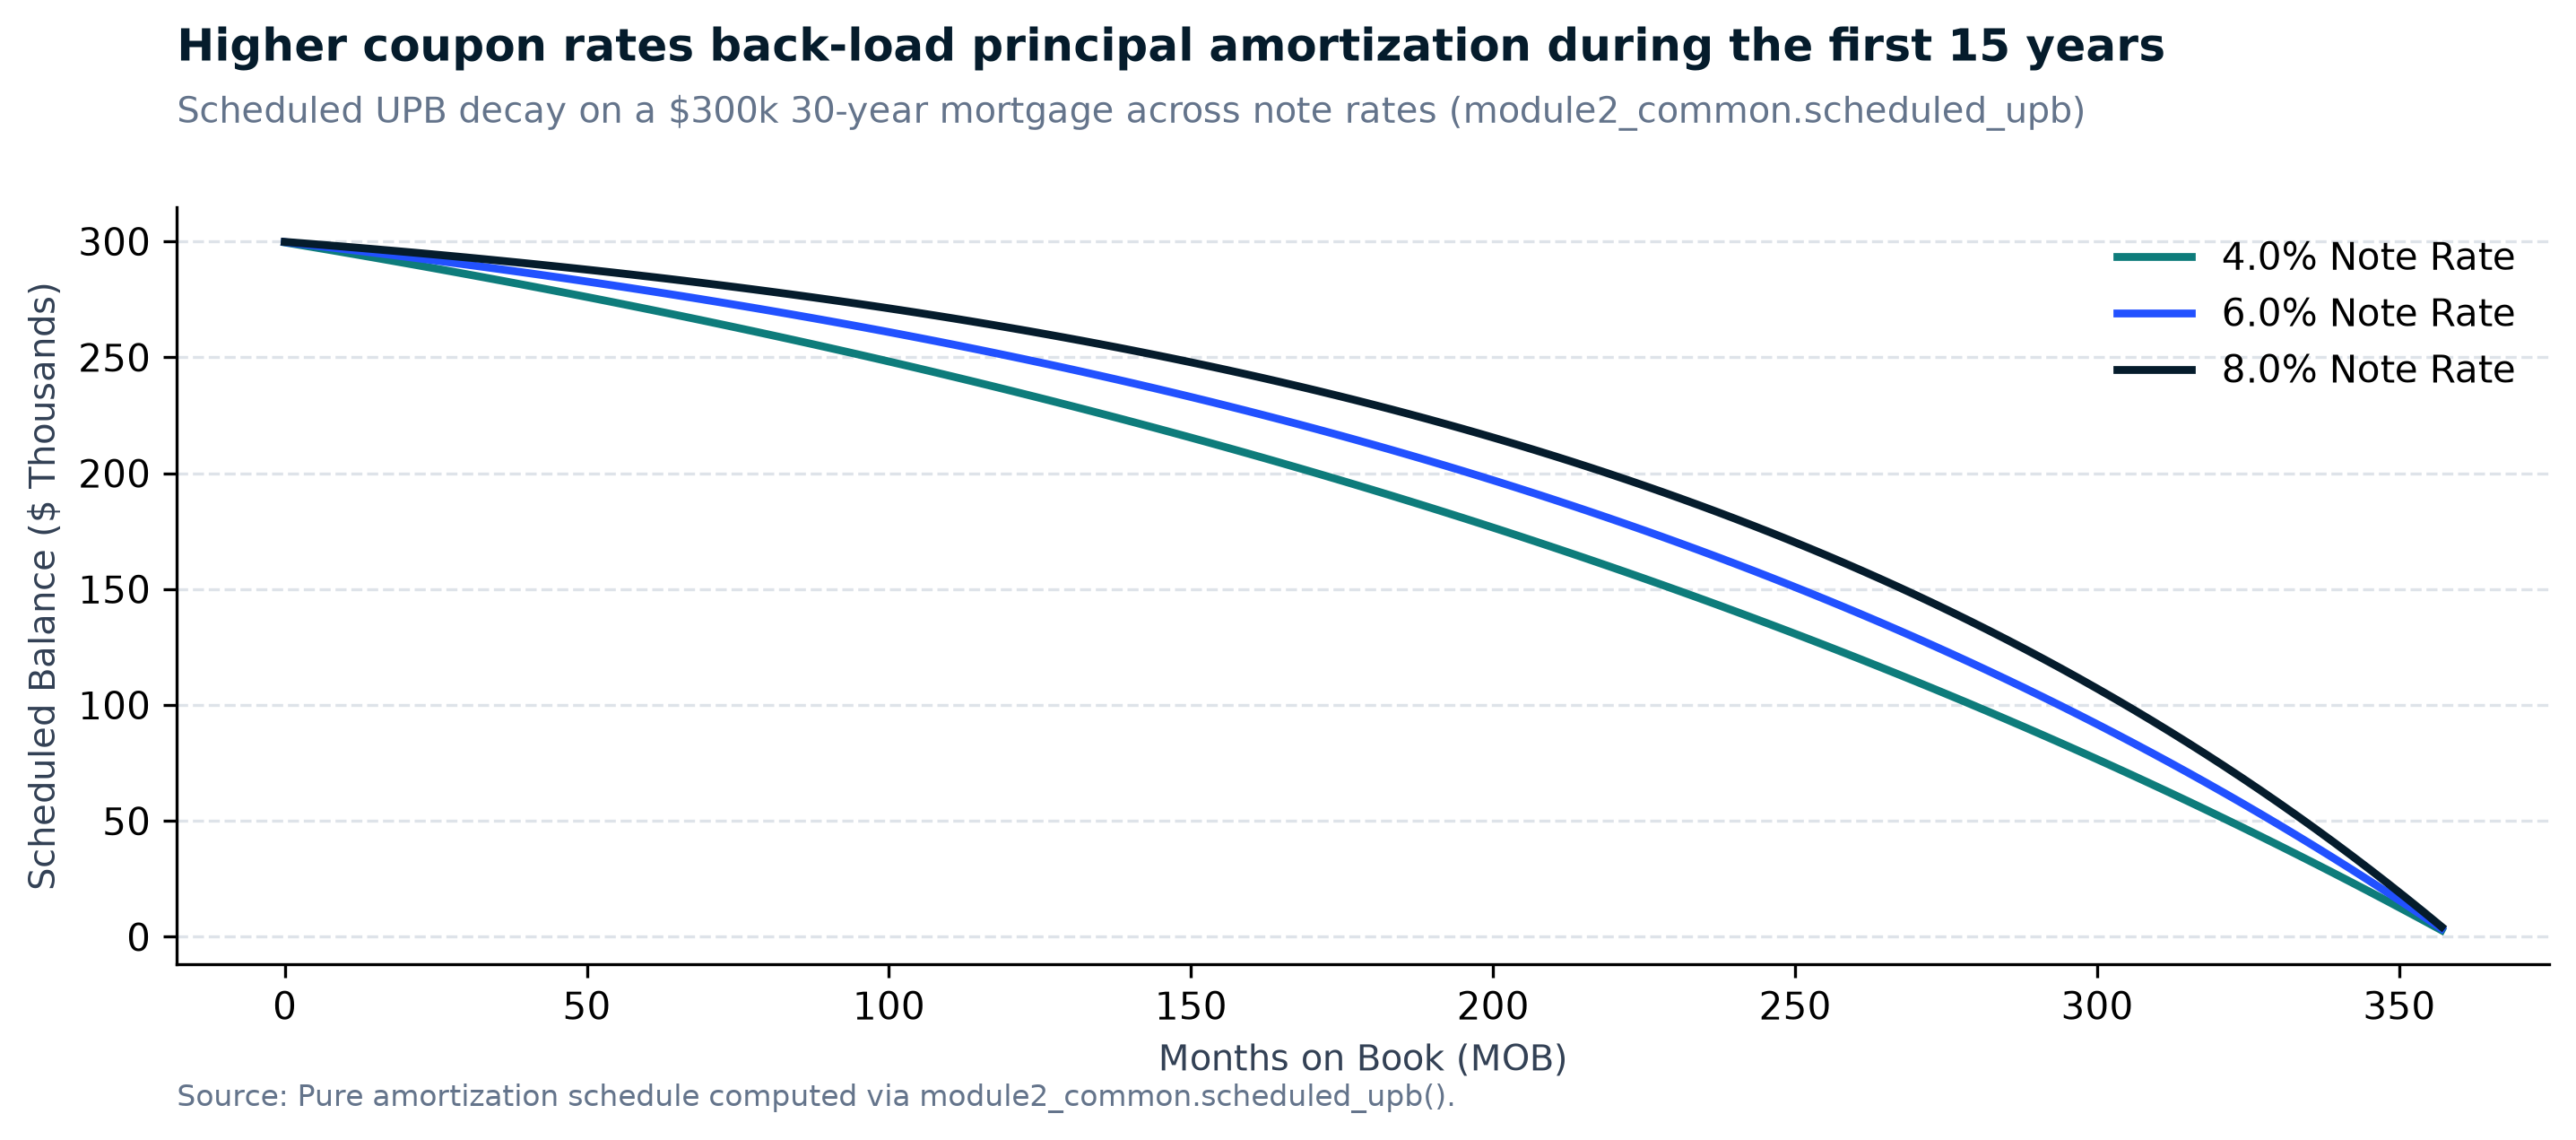

In [2]:
# Exercise COVID deferral hold cap and Wilson binomial confidence interval helpers
# Verify 6-month hold freeze rule on synthetic COVID sequence and check Wilson CI around a 2% PD
adj_dpd, in_hold = mc.covid_hold_months(
    mb=[0, 1, 2, 3, 4, 4, 4, 4, 5],
    plans=["", "F", "F", "F", "F", "F", "F", "F", ""],
    months=["2020-02", "2020-04", "2020-05", "2020-06", "2020-07", "2020-08", "2020-09", "2020-10", "2020-11"],
)
assert sum(in_hold) == 6, f"Expected 6 held months, got {sum(in_hold)}"
pt, lo, hi = mc.wilson_ci(events=20, total=1000)
print(f"COVID hold test PASS (held={sum(in_hold)}m, adj_dpd={adj_dpd}) | Wilson 95% CI (20/1000): {pt:.2%} [{lo:.2%}, {hi:.2%}]")

# Plot 30-year scheduled balance curves across three note rates at 300 dpi
# Compute scheduled_upb() from MOB 0..359 and display chart cleanly via BytesIO
ages = list(range(0, 360, 3))
fig, ax = plt.subplots(figsize=(9.8, 4.2), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
for r, col in [(4.0, "#0E7C7B"), (6.0, "#2251FF"), (8.0, "#051C2C")]:
    vals = [mc.scheduled_upb(300000.0, r, 360, m) / 1e3 for m in ages]
    ax.plot(ages, vals, linewidth=2.1, color=col, label=f"{r:.1f}% Note Rate", zorder=3)
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Months on Book (MOB)", fontsize=9.5, color="#334155")
ax.set_ylabel("Scheduled Balance ($ Thousands)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="upper right")
fig.text(0.07, 0.94, "Higher coupon rates back-load principal amortization during the first 15 years", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Scheduled UPB decay on a $300k 30-year mortgage across note rates (module2_common.scheduled_upb)", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: Pure amortization schedule computed via module2_common.scheduled_upb().", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()